In [4]:
import torch
g = torch.load('../data/lanl14argus_tgraph_csr.pt')

/tmp/ipykernel_4116038/4103712409.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  g = torch.load('../data/lanl14argus_tgraph_csr.pt')


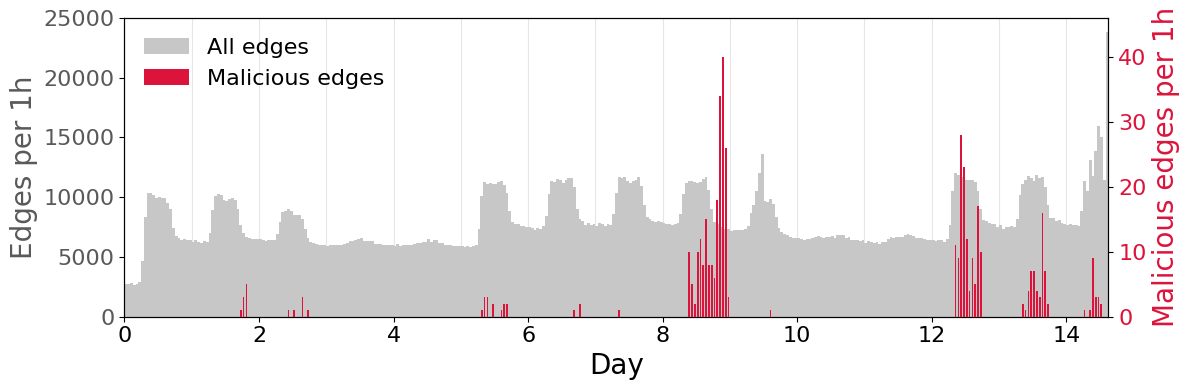

In [5]:
import numpy as np
import matplotlib.pyplot as plt


def plot_edge_frequency(data, bin_hours=1, unit=3600 * 24, unit_label="Day",
                        mal_log=False, label_size=14, tick_size=12):
    ts = np.asarray(data.ts, dtype=np.float64)
    mal = np.asarray(data.is_mal, dtype=np.int64)

    t_all = ts / unit
    t_mal = ts[mal] / unit

    # Shared bin edges so the two histograms line up exactly
    step = (bin_hours * 3600) / unit
    edges = np.arange(t_all.min(), t_all.max() + step, step)
    centers = (edges[:-1] + edges[1:]) / 2
    width = edges[1] - edges[0]

    all_counts, _ = np.histogram(t_all, bins=edges)
    mal_counts, _ = np.histogram(t_mal, bins=edges)

    fig, ax = plt.subplots(figsize=(12, 4))

    b1 = ax.bar(centers, all_counts, width=width, align="center",
                color="0.78", edgecolor="none", label="All edges", zorder=1)
    ax.set_xlabel(unit_label, fontsize=label_size)
    ax.set_ylabel(f"Edges per {bin_hours}h", color="0.35", fontsize=label_size)
    ax.tick_params(axis="y", labelcolor="0.35", labelsize=tick_size)
    ax.tick_params(axis="x", labelsize=tick_size)
    ax.set_xlim(edges[0], edges[-1])

    ax2 = ax.twinx()
    b2 = ax2.bar(centers, mal_counts, width=width * 0.6, align="center",
                 color="crimson", edgecolor="none", label="Malicious edges",
                 zorder=3)
    ax2.set_ylabel(f"Malicious edges per {bin_hours}h", color="crimson",
                   fontsize=label_size)
    ax2.tick_params(axis="y", labelcolor="crimson", labelsize=tick_size)
    if mal_log:
        ax2.set_yscale("log")
    else:
        ax2.set_ylim(0, max(mal_counts.max() * 1.15, 1))

    # Day gridlines
    for d in np.arange(np.floor(edges[0]), np.ceil(edges[-1]) + 1):
        ax.axvline(d, color="0.9", lw=0.8, zorder=0)

    ax2.set_zorder(ax.get_zorder() + 1)
    ax.patch.set_visible(False)
    ax.legend(handles=[b1, b2], loc="upper left", frameon=False, fontsize=tick_size)

    fig.tight_layout()
    return fig, (ax, ax2)


fig, _ = plot_edge_frequency(g, bin_hours=1, label_size=20, tick_size=16)

/tmp/ipykernel_4116038/1222725236.py:72: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  g = torch.load('../data/lanl14argus_tgraph_csr.pt')


41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of hosts seen (9528/13292)
7 days: 0.8814 of hosts seen (11716/13292)
41h: 0.7168 of h

/tmp/ipykernel_4116038/1222725236.py:74: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  g = torch.load('../data/optc-argus_tgraph_csr.pt')


5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)
5 Days: 0.9656 of hosts seen (786/814)


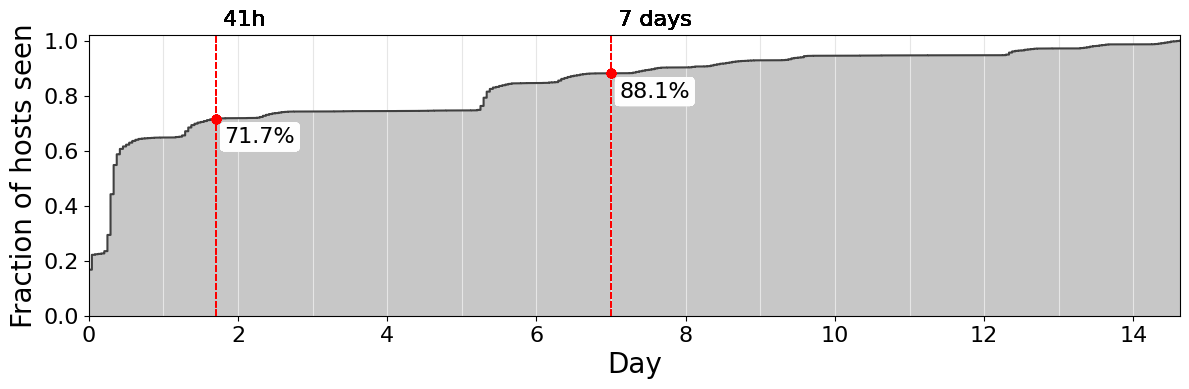

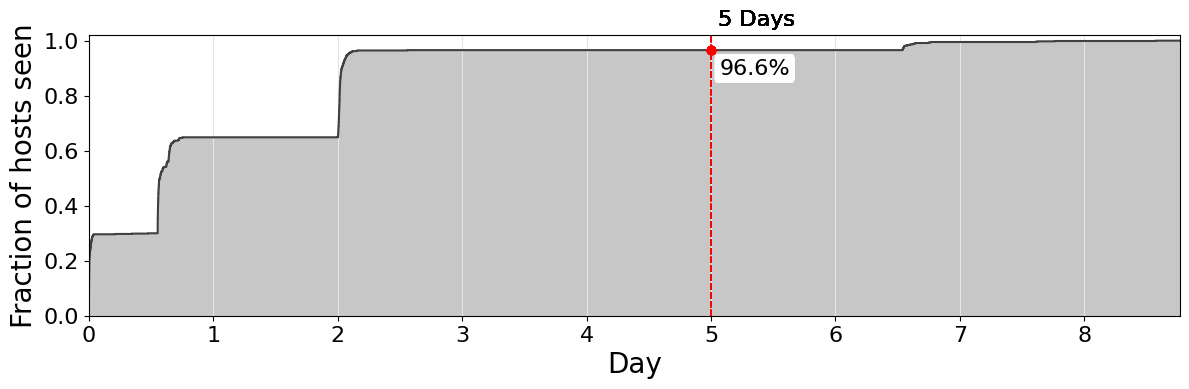

In [7]:
import numpy as np
import matplotlib.pyplot as plt


def first_seen(data):
    '''Earliest timestamp at which each node appears as either endpoint of an edge (inf if never).'''
    ts = np.asarray(data.ts, dtype=np.float64)
    dst = np.asarray(data.col, dtype=np.int64)
    if 'src' in data:
        src = np.asarray(data.src, dtype=np.int64)
    else:
        ptr = np.asarray(data.idxptr, dtype=np.int64)
        src = np.repeat(np.arange(ptr.size - 1), np.diff(ptr))
    n = int(data.x.shape[0])
    first = np.full(n, np.inf)
    np.minimum.at(first, src, ts)
    np.minimum.at(first, dst, ts)
    return first


def plot_host_cdf(data, unit=3600 * 24, unit_label="Day", label_size=20, tick_size=16,
                  all_nodes=False, marks=()):
    '''
    Fraction of hosts seen so far over time: starts at 0, rises by 1/|V| each time a host
    appears in the edge list for the first time, and ends at 1.

    all_nodes=False: |V| = hosts that appear in some edge (the curve ends at exactly 1).
    all_nodes=True:  |V| = data.x.shape[0], so hosts that never appear keep it below 1.
    marks: times (in `unit`s) to draw as dashed vertical lines, e.g. [41 / 24, 7] for the cutoffs.
    '''
    first = first_seen(data)
    seen = np.sort(first[np.isfinite(first)]) / unit
    n = first.size if all_nodes else seen.size

    ts = np.asarray(data.ts, dtype=np.float64) / unit
    t0, t1 = ts.min(), ts.max()

    # step function: 0 before the first host, k/|V| after the k-th, held to the end of the data
    x = np.concatenate([[t0], seen, [t1]])
    y = np.concatenate([[0], np.arange(1, seen.size + 1) / n, [seen.size / n]])

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.fill_between(x, y, step="post", color="0.78", lw=0)
    ax.step(x, y, where="post", color="0.25", lw=1.5)

    ax.set_xlim(t0, t1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel(unit_label, fontsize=label_size)
    ax.set_ylabel("Fraction of hosts seen", fontsize=label_size)
    ax.tick_params(labelsize=tick_size)

    # Day gridlines, as in plot_edge_frequency
    for d in np.arange(np.floor(t0), np.ceil(t1) + 1):
        ax.axvline(d, color="0.9", lw=0.8, zorder=1.5)   # over the fill, under the line
        for sec, label in marks:
            t = sec / unit
            frac = np.searchsorted(seen, t, side="right") / n   # step value at t: hosts seen by time t
            print(f"{label}: {frac:.4f} of hosts seen ({int(round(frac * n))}/{n})")

            ax.axvline(t, color="r", ls="--", lw=1.2, zorder=3)
            ax.text(t, 1.02, f" {label}", ha="left", va="bottom", fontsize=tick_size,
                    transform=ax.get_xaxis_transform())
            ax.plot(t, frac, "o", color="r", ms=6, zorder=4)
            ax.annotate(f"{frac:.1%}", (t, frac), xytext=(6, -6), textcoords="offset points",
                        ha="left", va="top", fontsize=tick_size, zorder=5,
                        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85))

    fig.tight_layout()
    return fig, ax


g = torch.load('../data/lanl14argus_tgraph_csr.pt')
fig, _ = plot_host_cdf(g, marks=((41 * 3600, "41h"), (7 * 86400, "7 days")))
g = torch.load('../data/optc-argus_tgraph_csr.pt')
fig, _ = plot_host_cdf(g, marks=((5*24 * 3600, "5 Days"),))
